![Python Banner](../../Image/05_07_Policy_Learners.png)


# 7.2 DR Policy Tree

PyCausalML's `DRPolicyTree` learns a deterministic treatment policy from doubly robust scores. Outcome regressions and a propensity model are cross-fitted, so the policy stays consistent if either nuisance model is correct. This is the tree policy used by EconML's DR policy learner.

## Overview

### What is DR Policy Tree?

PyCausalML's `DRPolicyTree` is a policy learning method that:

1. **Estimates CATEs** using doubly robust estimation (combines outcome regression and propensity scores)
2. **Learns a policy tree** that partitions the covariate space and assigns treatment to regions with positive expected CATE
3. **Is doubly robust**: Consistent if either the propensity model or outcome model is correct

### Key Features

- **Doubly robust**: Robust to misspecification of either the propensity or outcome model
- **Flexible ML models**: Can use any scikit-learn compatible model for outcome and propensity
- **Interpretable**: Tree structure provides clear decision rules
- **Policy evaluation**: Built-in methods to estimate policy value and regret
- **Uncertainty quantification**: Optional inference methods for policy estimates

### Business Setting

DR Policy Tree is ideal when:

- **Robustness needed**: You want protection against model misspecification
- **Rich covariates**: Many observed confounders to adjust for
- **Interpretable policies**: Clear decision rules for stakeholders
- **Binary treatment**: Treatment is yes/no

Common business applications:

- Customer targeting with rich feature sets
- Credit scoring with many risk factors
- Marketing personalization
- Healthcare treatment assignment

## Setup

Install the required packages:

In [1]:
import subprocess
import sys
from pathlib import Path

def _repo_root() -> Path:
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "pyproject.toml").is_file() and (cand / "src" / "pycausalml").is_dir():
            return cand
    raise FileNotFoundError(
        "PyCausalML repository was not found. Run this notebook from the repository."
    )

try:
    import pycausalml  # noqa: F401
    print("PyCausalML ready.")
except ImportError:
    root = _repo_root()
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", "-e", f"{root}[plot]"],
    )
    print("PyCausalML installed.")


PyCausalML ready.


In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.tree import plot_tree

from pycausalml import DRLearner, DRPolicyTree
from pycausalml.policy_learners import policy_value

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
print("Imported PyCausalML")


def show_policy_tree(model, feature_names, title, tree_index=None):
    """Draw a policy tree. ``tree_index`` selects one tree from a forest."""
    if getattr(model, "policy_", None) is None:
        print(f"{title}: constant policy = {model.constant_}")
        return
    estimator = model.policy_
    if tree_index is not None:
        estimator = estimator.estimators_[tree_index]
    fig, ax = plt.subplots(figsize=(14, 8))
    plot_tree(
        estimator,
        feature_names=list(feature_names),
        class_names=["control", "treat"],
        filled=True,
        rounded=True,
        impurity=False,
        ax=ax,
        fontsize=8,
    )
    ax.set_title(title)
    fig.tight_layout()
    plt.show()


Imported PyCausalML


## Example: Synthetic Policy Learning Data

Let's create synthetic data with heterogeneous treatment effects:

In [3]:
def create_policy_data(n_samples=1000, n_features=5, random_state=42):
    """
    Create synthetic data for policy learning.
    
    Treatment effect depends on covariates:
    - Positive effect for high values of X1
    - Negative effect for high values of X2
    """
    np.random.seed(random_state)
    
    # Generate covariates
    X = np.random.normal(0, 1, (n_samples, n_features))
    
    # True CATE: heterogeneous treatment effect
    tau = 2 * X[:, 0] - 1.5 * X[:, 1] + 0.5 * X[:, 2]
    
    # Treatment assignment (depends on covariates)
    propensity = 1 / (1 + np.exp(-(0.5 * X[:, 0] + 0.3 * X[:, 1])))
    T = np.random.binomial(1, propensity)
    
    # Outcome
    Y = 10 + np.sum(X[:, :3], axis=1) + tau * T + np.random.normal(0, 1, n_samples)
    
    # Create DataFrame
    feature_names = [f'X{i}' for i in range(n_features)]
    df = pd.DataFrame(X, columns=feature_names)
    df['T'] = T
    df['Y'] = Y
    df['tau_true'] = tau  # true CATE for evaluation
    
    return df

# Generate data
df = create_policy_data(n_samples=1000, n_features=5)
print(df.head())

      X0     X1    X2     X3     X4  T      Y  tau_true
0  0.497 -0.138 0.648  1.523 -0.234  1 12.988     1.525
1 -0.234  1.579 0.767 -0.469  0.543  1 11.757    -2.453
2 -0.463 -0.466 0.242 -1.913 -1.725  0  9.175    -0.107
3 -0.562 -1.013 0.314 -0.908 -1.412  0  9.330     0.552
4  1.466 -0.226 0.068 -1.425 -0.544  1 14.504     3.304


## Step 1: Train DR Learner

First, we train a doubly robust learner to estimate CATEs:

In [4]:
X = df[[f"X{i}" for i in range(5)]]
T = df["T"].to_numpy()
Y = df["Y"].to_numpy()
feature_names = list(X.columns)

dr_learner = DRLearner(
    learner="gbr",
    n_estimators=40,
    n_splits=3,
    random_state=42,
)
dr_learner.fit(X, T, Y)
cate_estimates = dr_learner.predict(X)

print("DR learner fitted")
print(f"CATE estimates shape: {cate_estimates.shape}")
print(f"Mean CATE: {cate_estimates.mean():.3f}")


DR learner fitted
CATE estimates shape: (1000,)
Mean CATE: 0.083


## Step 2: Train DR Policy Tree

Now we use the DR Policy Tree to learn a treatment policy:

In [5]:
policy_tree = DRPolicyTree(
    max_depth=3,
    n_splits=3,
    nuisance="gbr",
    n_estimators=40,
    random_state=42,
)
policy_tree.fit(X, T, Y)
print("DR policy tree fitted")
print(f"Training policy value (IPW): {policy_tree.training_policy_value():.3f}")


DR policy tree fitted
Training policy value (IPW): 11.168


## Step 3: Visualize the Policy Tree

The fitted tree is a scikit-learn classifier, so it can be drawn directly:

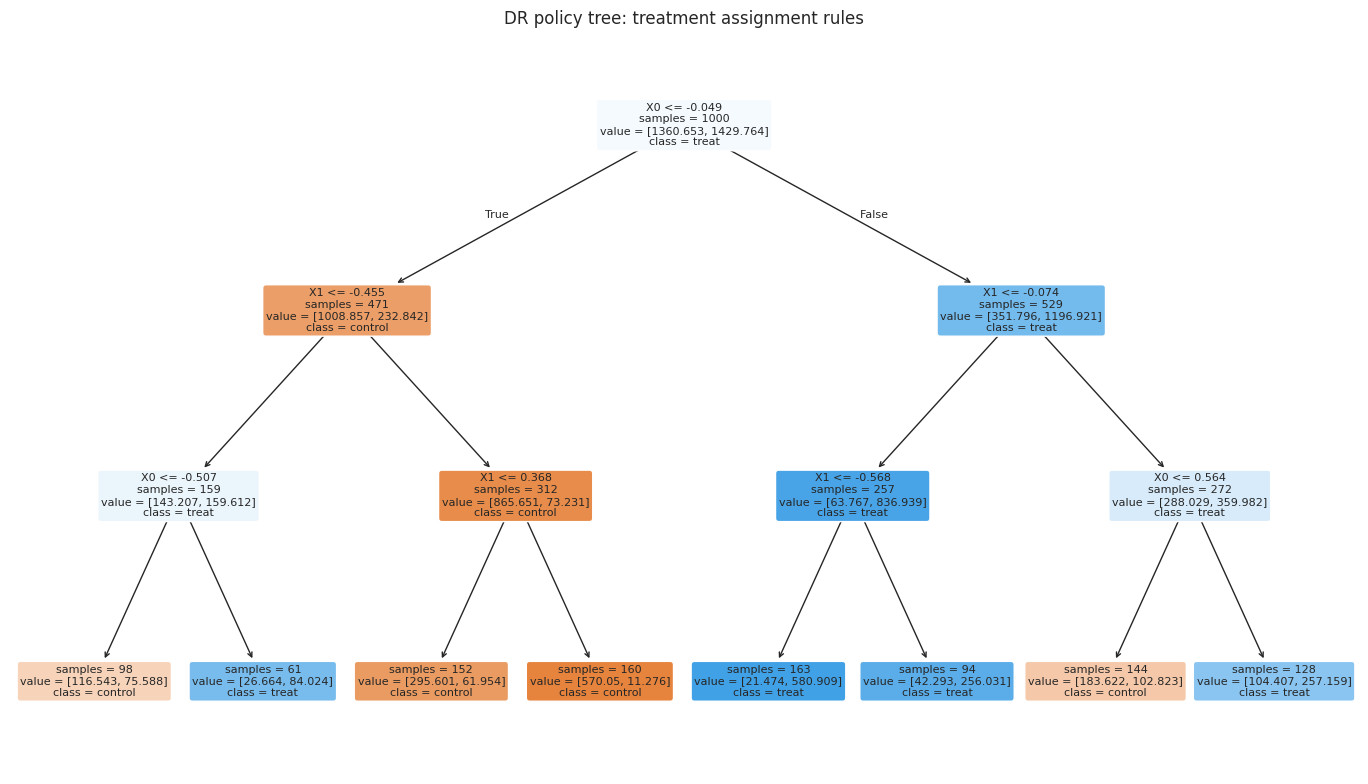

In [6]:
show_policy_tree(policy_tree, feature_names, "DR policy tree: treatment assignment rules")


The tree shows the decision rules. Leaf nodes show the recommended treatment (0 or 1) and the estimated policy value.

## Step 4: Predict Policy on New Data

Use the learned policy to make treatment decisions:

In [7]:
policy = policy_tree.predict(X)
df["policy"] = policy

print("Policy predictions:")
print(df[["X0", "X1", "X2", "T", "Y", "policy"]].head(10))
print(f"Treatment rate in data: {df['T'].mean():.3f}")
print(f"Policy treatment rate: {df['policy'].mean():.3f}")


Policy predictions:
      X0     X1     X2  T      Y  policy
0  0.497 -0.138  0.648  1 12.988       1
1 -0.234  1.579  0.767  1 11.757       0
2 -0.463 -0.466  0.242  0  9.175       1
3 -0.562 -1.013  0.314  0  9.330       0
4  1.466 -0.226  0.068  1 14.504       1
5  0.111 -1.151  0.376  1 13.414       1
6 -0.602  1.852 -0.013  0  9.490       0
7 -1.221  0.209 -1.960  1  3.388       0
8  0.738  0.171 -0.116  1 10.331       1
9 -0.720 -0.461  1.057  0  7.370       0
Treatment rate in data: 0.516
Policy treatment rate: 0.446


## Step 5: Evaluate Policy Value

Estimate the expected outcome under the learned policy:

In [8]:
learned_value = policy_tree.training_policy_value()
observed_value = policy_value(Y, T, T, policy_tree.e_hat_)
treat_all = policy_value(Y, T, np.ones_like(T), policy_tree.e_hat_)

print(f"Learned policy value (IPW): {learned_value:.3f}")
print(f"Observed assignment value (IPW): {observed_value:.3f}")
print(f"Treat-all value (IPW): {treat_all:.3f}")
print(f"Gain over observed assignment: {learned_value - observed_value:.3f}")


Learned policy value (IPW): 11.168
Observed assignment value (IPW): 20.108
Treat-all value (IPW): 10.201
Gain over observed assignment: -8.940


## Step 6: Compare with Oracle Policy

Compare with the oracle policy (using true CATEs):

In [9]:
oracle_policy = (df["tau_true"].to_numpy() > 0).astype(int)
oracle_value = policy_value(Y, T, oracle_policy, policy_tree.e_hat_)
agree = float((df["policy"].to_numpy() == oracle_policy).mean())

print(f"Oracle policy value (IPW): {oracle_value:.3f}")
print(f"Learned policy value (IPW): {learned_value:.3f}")
print(f"Regret: {oracle_value - learned_value:.3f}")
print(f"Agreement with the oracle: {agree:.3f}")


Oracle policy value (IPW): 11.402
Learned policy value (IPW): 11.168
Regret: 0.235
Agreement with the oracle: 0.877


## Step 7: Different ML Models

Try different ML models for the outcome and propensity models:

In [10]:
policy_tree_rf = DRPolicyTree(
    max_depth=3,
    n_splits=3,
    nuisance="rf",
    n_estimators=40,
    random_state=42,
)
policy_tree_rf.fit(X, T, Y)
print(f"Policy value with random-forest nuisances: {policy_tree_rf.training_policy_value():.3f}")


Policy value with random-forest nuisances: 11.204


## Hyperparameter Tuning

Key hyperparameters for DR Policy Tree:

- **max_depth**: Maximum tree depth (controls complexity)
- **min_samples_leaf**: Minimum samples per leaf (controls overfitting)
- **min_impurity_decrease**: Minimum impurity decrease for splits
- **max_features**: Features to consider for splits

In [11]:
for depth in [2, 3, 4, 5]:
    pt = DRPolicyTree(
        max_depth=depth,
        n_splits=2,
        nuisance="gbr",
        n_estimators=25,
        random_state=42,
    )
    pt.fit(X, T, Y)
    print(f"Depth {depth}: policy value = {pt.training_policy_value():.3f}")


Depth 2: policy value = 11.034


Depth 3: policy value = 11.356


Depth 4: policy value = 11.299


Depth 5: policy value = 11.299


## Common Pitfalls

### 1. Poor Overlap

If propensity scores don't overlap, doubly robust methods can be unstable.

**Solution**: Check overlap, trim extreme propensity scores, or use trimming.

### 2. Overfitting

Deep trees may overfit to noise in the CATE estimates.

**Solution**: Use shallower trees, increase min_samples_leaf, or use policy forests.

### 3. Model Misspecification

While doubly robust, if both models are misspecified, estimates can be biased.

**Solution**: Use flexible ML models, validate model fit, consider ensemble methods.

## When to Use DR Policy Tree

DR Policy Tree is the right choice when:

- **Robustness needed**: Protection against model misspecification
- **Rich covariates**: Many observed confounders
- **Interpretable policies**: Clear decision rules
- **Binary treatment**: Treatment is yes/no

Consider alternatives when:

- Multi-armed treatment → Multi-arm policy methods
- Complex heterogeneity → Policy forests or neural policies
- Weak overlap → Propensity score trimming or alternative methods

## Summary

PyCausalML's `DRPolicyTree` is a robust, interpretable way to learn a treatment policy from doubly robust scores.

**Key takeaways:**

- DR Policy Tree is doubly robust — consistent if either model is correct
- Combines outcome regression with propensity score weighting
- Provides interpretable decision rules through tree structure
- Can use any scikit-learn compatible ML models
- Includes policy value estimation for evaluation
- Hyperparameters control complexity and overfitting
- Always validate policies on held-out data
- Consider policy forests for more robust policies

## Scientific Terminology

Plain-language definitions for the terms in this tutorial are in the [scientific terminology glossary](../00-scientific-terminology-glossary.qmd).
